In [ ]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\ProgramData\python.exe -m pip install --upgrade pip' command.


In [ ]:
%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

You should consider upgrading via the 'c:\ProgramData\python.exe -m pip install --upgrade pip' command.


'=== K-means Clustering Results ==='

,Recency,Frequency,Monetary,R,F,M,Count,%
Cluster_Label,,,,,,,,
At Risk,130.94,4.12,1320.84,3.80,5.00,3.17,10072,16.04%
Best,216.76,1.45,2301.28,3.08,2.89,4.88,11414,18.17%
Lost,449.80,1.26,1028.05,1.41,2.03,2.49,18256,29.07%
New,112.75,1.27,967.86,3.89,2.95,2.33,23062,36.72%


'=== Scale-based Segmentation Results ==='

,Recency,Frequency,Monetary,R,F,M,RFM_Combine,RFM_Score,Count,%
RFM_Segment,,,,,,,,,,
Lost,396.29,1.08,965.09,1.71,1.67,2.19,311,5.58,20202,32.17%
At Risk,228.62,1.46,1174.85,2.94,2.88,2.70,314,8.52,14440,22.99%
Potential,150.77,1.98,1349.82,3.61,3.67,3.21,253,10.49,14426,22.97%
Best,81.71,2.84,1800.02,4.35,4.37,4.17,445,12.89,13736,21.87%


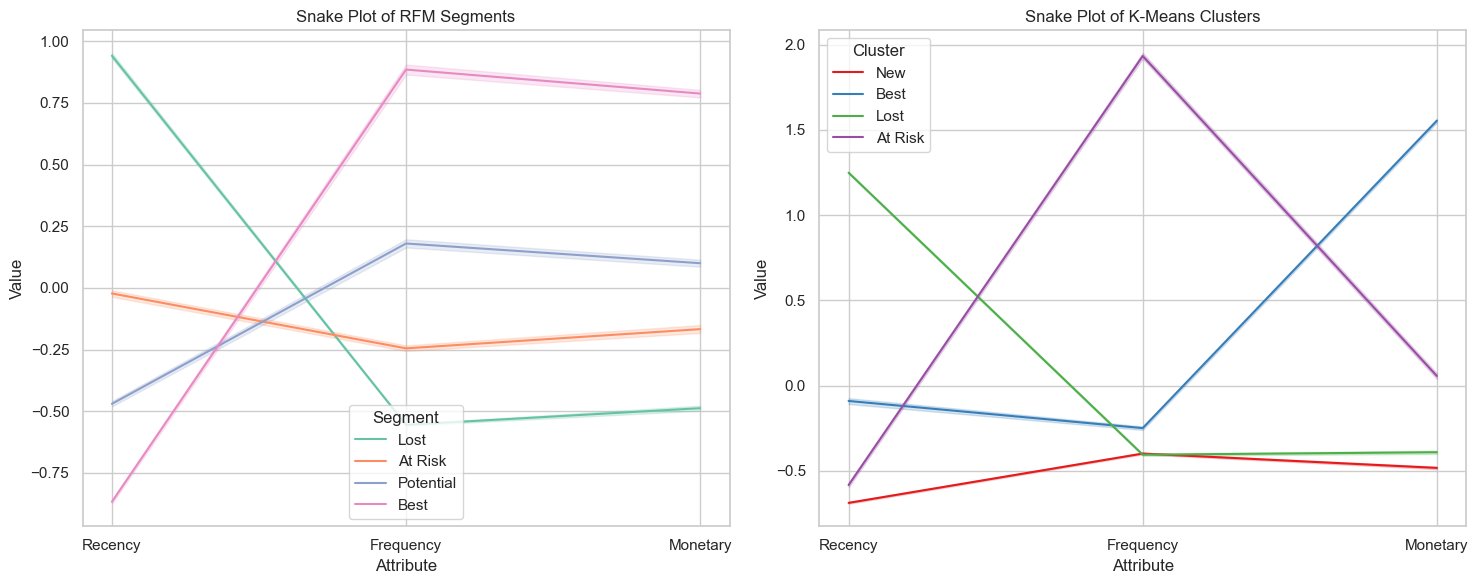

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 讀取資料
df = pd.read_excel("Q1_data.xlsx")

# 資料預處理
df = df.dropna(subset=['MemberID', 'OrderTotal'])
df['OrderTotal'] = df['OrderTotal'].apply(lambda x: max(0, x))
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
snapshot_date = df['OrderDate'].max() + pd.Timedelta(days=1)

# 計算 RFM (Monetary 使用平均訂單金額 AOV)
rfm = df.groupby('MemberID').agg({
    'OrderDate': lambda x: (snapshot_date - x.max()).days,
    'MemberID': 'count',
    'OrderTotal': 'mean'
})
rfm.columns = ['Recency', 'Frequency', 'Monetary']
rfm = rfm[rfm['Monetary'] > 0]

# 排除離群值 (1.5 * IQR)
def remove_outliers(df, cols):
    for col in cols:
        Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
        IQR = Q3 - Q1
        df = df[(df[col] >= Q1 - 1.5 * IQR) & (df[col] <= Q3 + 1.5 * IQR)]
    return df
rfm_clean = remove_outliers(rfm, ['Recency', 'Frequency', 'Monetary']).copy()

# K-means 分群
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_clean)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm_clean['Cluster'] = kmeans.fit_predict(rfm_scaled)

cluster_means = rfm_clean.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean()
cluster_map = {}

# Recency 最高的那群定義為 Lost（流失客戶）
lost_cluster = cluster_means['Recency'].idxmax()
cluster_map[lost_cluster] = 'Lost'

remaining = [c for c in range(4) if c != lost_cluster]

# 剩餘之中，Monetary (消費金額) 最高的那群定義為 Best（最佳大戶客戶）
best_cluster = cluster_means.loc[remaining, 'Monetary'].idxmax()
cluster_map[best_cluster] = 'Best'

remaining = [c for c in remaining if c != best_cluster]

# 剩餘兩個之中，Recency 較低的是 New（新客戶），較高的是 At Risk（風險客戶）
if cluster_means.loc[remaining[0], 'Recency'] < cluster_means.loc[remaining[1], 'Recency']:
    new_cluster, risk_cluster = remaining[0], remaining[1]
else:
    new_cluster, risk_cluster = remaining[1], remaining[0]

cluster_map[new_cluster] = 'New'
cluster_map[risk_cluster] = 'At Risk'

rfm_clean['Cluster_Label'] = rfm_clean['Cluster'].map(cluster_map)

rfm_clean['R'] = pd.qcut(rfm_clean['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm_clean['F'] = pd.qcut(rfm_clean['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm_clean['M'] = pd.qcut(rfm_clean['Monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)

# 輸出範例 1
ex1 = rfm_clean.groupby('Cluster_Label').agg({
    'Recency': 'mean', 'Frequency': 'mean', 'Monetary': 'mean',
    'R': 'mean', 'F': 'mean', 'M': 'mean', 'Cluster': 'count'
}).round(2)
ex1.rename(columns={'Cluster': 'Count'}, inplace=True)
ex1['%'] = (ex1['Count'] / ex1['Count'].sum() * 100).map('{:.2f}%'.format)

display("=== K-means Clustering Results ===")
display(ex1)

# 輸出範例 2 
rfm_clean['RFM_Score'] = rfm_clean['R'] + rfm_clean['F'] + rfm_clean['M']
rfm_clean['RFM_Combine'] = rfm_clean['R'].astype(str) + rfm_clean['F'].astype(str) + rfm_clean['M'].astype(str)
rfm_clean['RFM_Segment'] = pd.qcut(rfm_clean['RFM_Score'], 4, labels=['Lost', 'At Risk', 'Potential', 'Best'])

ex2 = rfm_clean.groupby('RFM_Segment', observed=False).agg({
    'Recency': 'mean', 'Frequency': 'mean', 'Monetary': 'mean',
    'R': 'mean', 'F': 'mean', 'M': 'mean',
    'RFM_Combine': 'first', 'RFM_Score': 'mean', 'Cluster': 'count'
}).round(2)
ex2.rename(columns={'Cluster': 'Count'}, inplace=True)
ex2['%'] = (ex2['Count'] / ex2['Count'].sum() * 100).map('{:.2f}%'.format)

display("=== Scale-based Segmentation Results ===")
display(ex2)

# 輸出範例 3 
rfm_scaled_df = pd.DataFrame(rfm_scaled, index=rfm_clean.index, columns=['Recency', 'Frequency', 'Monetary'])
rfm_scaled_df['Cluster_Label'] = rfm_clean['Cluster_Label']
rfm_scaled_df['RFM_Segment'] = rfm_clean['RFM_Segment']

rfm_melted_kmeans = pd.melt(rfm_scaled_df.reset_index(), 
                            id_vars=['MemberID', 'Cluster_Label'], 
                            value_vars=['Recency', 'Frequency', 'Monetary'], 
                            var_name='Attribute', 
                            value_name='Value')

rfm_melted_segment = pd.melt(rfm_scaled_df.reset_index(), 
                           id_vars=['MemberID', 'RFM_Segment'], 
                           value_vars=['Recency', 'Frequency', 'Monetary'], 
                           var_name='Attribute', 
                           value_name='Value')

sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
sns.lineplot(x='Attribute', y='Value', hue='RFM_Segment', data=rfm_melted_segment, palette='Set2')
plt.title('Snake Plot of RFM Segments')
plt.legend(title='Segment')

plt.subplot(1, 2, 2)
sns.lineplot(x='Attribute', y='Value', hue='Cluster_Label', data=rfm_melted_kmeans, palette='Set1')
plt.title('Snake Plot of K-Means Clusters')
plt.legend(title='Cluster')

plt.tight_layout()
plt.show()